# Traffic CCTV — BMD-45 **RT-DETRv2-X**, batch inference trên 5 camera (**chỉ ảnh all_boxes**)

**Giữ nguyên cấu trúc 17 cell của notebook BMD-45 batch gốc:** đọc toàn bộ `frame_*` từ đúng 5 camera; mỗi frame xuất **một ảnh all_boxes**; preview 1 ảnh/camera; ZIP chứa ảnh và bốn file `manifest.csv`, `camera_summary.csv`, `errors.csv`, `run_config.json`.

**Chỉ đổi detector sang checkpoint BMD-45 RT-DETRv2-X** (`weights/RT-DETRv2/best.pth`). Loader được lấy từ notebook 1 ảnh `detect-n(6).ipynb` mà bạn đã chạy thành công: bao gồm sửa mismatch **14 class (ID 13 = Other)** của checkpoint, `strict=True`, preprocessing/postprocessor chính thức **640×640, không áp dụng NMS**. Các cell vẽ box, loop 5 camera, xuất báo cáo và nén ZIP giữ nguyên 100% so với bản batch gốc.

**Kaggle:** Add Input dataset → GPU + Internet → Run All → tải file `traffic_detection_RTDETRv2_BMD45_5cams_all_boxes_only.zip` trong `/kaggle/working/`.

**Lần đầu:** Nếu cell dependencies yêu cầu restart, vào **Run → Restart Session**, sau đó **Run All** lại (giống notebook RT-DETRv2 một ảnh).

Count trong manifest là số prediction, không phải ground truth hoặc flow/OD/density thực tế.


In [1]:
# 0) Kaggle dependency preflight (Python 3.13; không thay Torch/CUDA có sẵn)
# Cố định cặp Hugging Face để tránh pip nâng cấp gây trộn file giữa các version.
# Nếu có thay đổi package, cell sẽ DỪNG CÓ CHỦ ĐÍCH: Restart Session rồi Run All.
# Lần chạy thứ hai sẽ nhận diện các version đã đúng và không cài lại.
import sys, subprocess, importlib.metadata as md

PINNED = {
    "huggingface_hub": "0.34.4",
    "transformers": "4.51.3",
    "tokenizers": "0.21.2",
    "calflops": "0.3.2",
}

def get_version(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return None

def check_clean_import():
    # Process riêng: phát hiện site-packages bị trộn phiên bản ngay cả khi metadata có vẻ đúng.
    probe = r"""
from huggingface_hub import hf_hub_download
from transformers import AutoConfig
from calflops import calculate_flops
from PIL import Image
import torch, torchvision, numpy, pandas, matplotlib, yaml
print('DEPENDENCY_IMPORT_OK')
"""
    proc = subprocess.run([sys.executable, "-c", probe], text=True,
                          capture_output=True)
    return proc.returncode == 0, (proc.stdout + proc.stderr)[-2500:]

mismatched = {name: (get_version(name), pinned)
              for name, pinned in PINNED.items()
              if get_version(name) != pinned}
try:
    import PIL
    pillow_too_new = int(PIL.__version__.split(".")[0]) >= 13
except Exception:
    pillow_too_new = True

ok, diagnostic = check_clean_import()
if mismatched or pillow_too_new or not ok:
    print("Cần sửa môi trường:", mismatched)
    if not ok:
        print("Import probe:", diagnostic)
    # Reinstall các distribution dễ gây lỗi 'mixed old/new files' mà KHÔNG động đến torch.
    core = [f"{k}=={v}" for k, v in PINNED.items()]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check",
                    "--force-reinstall", "--no-deps", *core], check=True)
    # Cài/đồng bộ dependency phụ, vẫn giữ pin core và không nâng Pillow lên 13.
    extras = [
        *core,
        "pillow>=10.4,<13", "pandas", "matplotlib", "PyYAML", "scipy",
        "pycocotools", "faster-coco-eval>=1.6.6", "tensorboard", "loguru",
    ]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check",
                    "--upgrade-strategy", "only-if-needed", *extras], check=True)
    ok_after, diagnostic_after = check_clean_import()
    if not ok_after:
        raise RuntimeError("Đã cài nhưng probe vẫn thất bại:\n" + diagnostic_after)
    print("\nĐÃ CÀI XONG. BẮT BUỘC: Kaggle → Run → Restart Session, rồi Run All từ đầu.")
    # Có thể còn module của phiên bản cũ trong kernel hiện tại.
    raise SystemExit("Restart Session một lần để dùng dependency đã cài (không phải lỗi model).")

print("Dependencies OK; không cần cài lại.")
for name in PINNED:
    print(f"  {name}: {get_version(name)}")
print("  pillow:", get_version("pillow"))
print("  torch (giữ nguyên Kaggle):", get_version("torch"))
print("  torchvision (giữ nguyên Kaggle):", get_version("torchvision"))


Dependencies OK; không cần cài lại.
  huggingface_hub: 0.34.4
  transformers: 4.51.3
  tokenizers: 0.21.2
  calflops: 0.3.2
  pillow: 12.3.0
  torch (giữ nguyên Kaggle): 2.11.0+cu128
  torchvision (giữ nguyên Kaggle): 0.26.0+cu128


## 1) Cấu hình

`INPUT_ROOT` là thư mục cha của 5 thư mục camera; notebook có fallback tìm trong `/kaggle/input`.

Mặc định `OUTPUT_IMAGE_FORMAT="png"` giữ chất lượng ảnh. Có thể đổi sang `"jpg"` để giảm dung lượng ZIP mà **không ảnh hưởng kết quả inference**, chỉ thay đổi chất lượng lưu ảnh. `MAX_FRAMES_PER_CAMERA=None` chạy toàn bộ. Không có tùy chọn vẽ ảnh riêng cho xe hai bánh hoặc crowded zoom.

In [2]:
INPUT_ROOT = "/kaggle/input/datasets/rykanny/traffic-benchmark/TEST_traffic_camera_5_locations"
CAMERA_FOLDERS = [
    "Cam_Ly_Thuong_Kiet_Bac_Hai",
    "Cam_Thanh_Thai_To_Hien_Thanh",
    "Cam_To_Hien_Thanh_1",
    "Cam_To_Hien_Thanh_2",
    "Cam_To_Hien_Thanh_Su_Van_Hanh",
]

# RT-DETRv2-X: checkpoint BMD-45, nạp theo notebook 1 ảnh đã chạy trên Kaggle.
MODEL_CHOICE = "rtdetrv2_x"
LOCAL_WEIGHTS_PATH = ""  # Tùy chọn: /kaggle/input/.../best.pth nếu đã tải sẵn

# RT-DETRv2-X yêu cầu preprocessing 640 x 640 (khác YOLO).
IMAGE_SIZE = 640
CONFIDENCE = 0.12
NMS_IOU = 0.65              # Chỉ lưu metadata; DETR không dùng NMS
MAX_DETECTIONS = 300         # Giới hạn số query của RT-DETRv2
TEST_TIME_AUGMENTATION = False # RT-DETRv2 notebook gốc không dùng TTA

# Vẽ MỘT ảnh all_boxes trên mỗi frame
SHOW_CONFIDENCE_ON_BOX = False
SHOW_INDEX_ON_BOX = True
OUTPUT_IMAGE_FORMAT = "png"      # "png" hoặc "jpg"
JPEG_QUALITY = 92

# Batch, log, output ZIP; dùng tên mới để không lẫn với run cũ có 3 loại ảnh
MAX_FRAMES_PER_CAMERA = None      # None = TẤT CẢ; đặt 2 để test nhanh
PREVIEW_PER_CAMERA = 1           # 1 preview/camera (hiển thị, KHÔNG lưu ảnh phụ)
LOG_EVERY_N_FRAMES = 20
SKIP_COMPLETED_FRAMES = False    # Detect lại để luôn hiện preview như bản gốc
OUTPUT_DIR = "/kaggle/working/traffic_detection_RTDETRv2_BMD45_all_boxes_only"
ZIP_PATH = "/kaggle/working/traffic_detection_RTDETRv2_BMD45_5cams_all_boxes_only.zip"


## 2) Kiểm tra GPU và **quét đúng 5 thư mục** (chỉ `frame_*` là ảnh)

In [3]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import hashlib, json, re, time, zipfile, sys, subprocess, importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
import torchvision.transforms as T
from huggingface_hub import hf_hub_download

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
FRAME_PREFIX = "frame_"
input_root = Path(INPUT_ROOT)
if not input_root.is_dir():
    candidates = [p for p in Path("/kaggle/input").rglob("TEST_traffic_camera_5_locations") if p.is_dir()]
    if not candidates:
        raise FileNotFoundError(
            f"Không thấy INPUT_ROOT: {INPUT_ROOT}. Hãy Add Input dataset traffic-benchmark "
            "và kiểm tra thư mục trong thanh bên phải của Kaggle."
        )
    valid = [p for p in candidates if all((p / cam).is_dir() for cam in CAMERA_FOLDERS)]
    if len(valid) != 1:
        raise RuntimeError(f"Không thể tự chọn duy nhất dataset 5 camera. Candidates: {candidates}. Hãy sửa INPUT_ROOT.")
    input_root = valid[0]
    print(f"Đã tự tìm thấy dataset tại: {input_root}")

missing = [cam for cam in CAMERA_FOLDERS if not (input_root / cam).is_dir()]
if missing:
    raise FileNotFoundError(f"Thiếu thư mục camera: {missing}. INPUT_ROOT hiện tại: {input_root}")

# Không quét các nhánh ngoài CAMERA_FOLDERS; loại summary.json, .csv, v.v. theo extension + prefix.
camera_files = {}
for cam in CAMERA_FOLDERS:
    frames = sorted(
        p for p in (input_root / cam).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        and p.name.lower().startswith(FRAME_PREFIX)
    )
    camera_files[cam] = frames if MAX_FRAMES_PER_CAMERA is None else frames[:MAX_FRAMES_PER_CAMERA]

inventory = pd.DataFrame([
    {"camera": cam, "frames_selected": len(camera_files[cam])}
    for cam in CAMERA_FOLDERS
])
print("INPUT_ROOT:", input_root)
display(inventory)
total_frames = int(inventory.frames_selected.sum())
print("TỔNG FRAME:", total_frames)
if total_frames == 0:
    raise RuntimeError("Không có ảnh frame_* trong 5 thư mục. Kiểm tra tên file và INPUT_ROOT.")

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE.startswith("cuda") else "CPU (DETR-X sẽ rất chậm; nên bật GPU)")
if OUTPUT_IMAGE_FORMAT.lower() not in {"png", "jpg"}:
    raise ValueError("OUTPUT_IMAGE_FORMAT phải là 'png' hoặc 'jpg'.")


INPUT_ROOT: /kaggle/input/datasets/rykanny/traffic-benchmark/TEST_traffic_camera_5_locations


,camera,frames_selected
0,Cam_Ly_Thuong_Kiet_Bac_Hai,6
1,Cam_Thanh_Thai_To_Hien_Thanh,5
2,Cam_To_Hien_Thanh_1,6
3,Cam_To_Hien_Thanh_2,6
4,Cam_To_Hien_Thanh_Su_Van_Hanh,6


TỔNG FRAME: 29
Device: Tesla T4


## 3) Nạp **một lần** checkpoint BMD-45 RT-DETRv2-X (đúng loader notebook 1 ảnh)


In [4]:
# Checkpoint được công bố công khai bởi AIM@IISc, Hugging Face.
BMD45_REPO = "iisc-aim/BMD-45"
BMD45_REVISION = "ec06f3dfbc5c896100265d38917cd49a996f41ec"  # revision đã tải và kiểm SHA ở notebook gốc
WEIGHTS_FILE = "weights/RT-DETRv2/best.pth"
EXPECTED_SHA256 = "c8dfcace8630fd6ca6f03eb501f09a46fd642ea1725e089edfa6a161cc2a88fd"
MODEL_CONFIG_FILE = "configs/RT-DETRv2/rtdetrv2_r101vd_6x_bmd-45.yaml"
DATASET_CONFIG_FILE = "configs/RT-DETRv2/bmd-45-dataset.yaml"
REPO_URL = "https://github.com/lyuwenyu/RT-DETR.git"
REPO_FOLDER = "RT-DETR"
REPO_SUBFOLDER = "rtdetrv2_pytorch"
EXPECTED_MODEL_CHOICE = "rtdetrv2_x"
assert MODEL_CHOICE == EXPECTED_MODEL_CHOICE

if LOCAL_WEIGHTS_PATH.strip():
    weights_path = Path(LOCAL_WEIGHTS_PATH)
    if not weights_path.is_file():
        raise FileNotFoundError(f"LOCAL_WEIGHTS_PATH không tồn tại: {weights_path}")
else:
    print("Đang tải BMD-45:", WEIGHTS_FILE)
    weights_path = Path(hf_hub_download(repo_id=BMD45_REPO, filename=WEIGHTS_FILE, revision=BMD45_REVISION))

# Kiểm toàn bộ file bằng streaming SHA256; tránh dùng nhầm checkpoint COCO hoặc tải chưa hoàn tất.
digest = hashlib.sha256()
with weights_path.open("rb") as fp:
    for chunk in iter(lambda: fp.read(4 * 1024 * 1024), b""):
        digest.update(chunk)
actual_sha = digest.hexdigest()
if actual_sha.lower() != EXPECTED_SHA256.lower():
    raise RuntimeError(
        f"Sai SHA256 của checkpoint BMD-45!\nExpected: {EXPECTED_SHA256}\nActual: {actual_sha}\n"
        "Không dùng file này; kiểm tra lại nguồn weights."
    )
print("Checkpoint:", weights_path)
print("Size (MiB):", round(weights_path.stat().st_size / 1024**2, 2))
print("SHA256 OK:", actual_sha)

# Download các YAML do nhóm tác giả BMD-45 công bố.
bmd_model_cfg = Path(hf_hub_download(repo_id=BMD45_REPO, filename=MODEL_CONFIG_FILE, revision=BMD45_REVISION))
bmd_dataset_cfg = Path(hf_hub_download(repo_id=BMD45_REPO, filename=DATASET_CONFIG_FILE, revision=BMD45_REVISION))
bmd_classes_path = Path(hf_hub_download(repo_id=BMD45_REPO, filename="bmd_classes.txt", revision=BMD45_REVISION))
class_lines = [s.strip() for s in bmd_classes_path.read_text(encoding="utf-8").splitlines() if s.strip()]
class_names = {i: name for i, name in enumerate(class_lines)}
assert len(class_names) == 13, f"bmd_classes.txt phải có 13 nhãn, nhận được {len(class_names)}"
assert class_names[7].lower() == "two-wheeler", "Class ID 7 không khớp bmd_classes.txt"

# Clone repo kiến trúc gốc, KHÔNG clone dataset 45 camera.
third_party = Path("/kaggle/working/bmd45_detector_sources")
third_party.mkdir(parents=True, exist_ok=True)
repo_root = third_party / REPO_FOLDER
if not (repo_root / ".git").is_dir():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_root)], check=True)
code_root = repo_root / REPO_SUBFOLDER if REPO_SUBFOLDER else repo_root
if not (code_root / "src" / "core").is_dir():
    raise RuntimeError(f"Repo chính thức thiếu src/core tại {code_root}")

# NOTE: HF lưu *.yaml nhưng __include__ tham chiếu *.yml; chuyển sang tên đúng.
dataset_target = code_root / "configs/dataset/bmd-45-dataset.yml"
model_target = code_root / "configs/rtdetrv2/rtdetrv2_r101vd_6x_bmd-45.yml"
dataset_target.parent.mkdir(parents=True, exist_ok=True)
model_target.parent.mkdir(parents=True, exist_ok=True)
dataset_target.write_bytes(bmd_dataset_cfg.read_bytes())
model_target.write_bytes(bmd_model_cfg.read_bytes())

import yaml
raw_ds = yaml.safe_load(dataset_target.read_text(encoding="utf-8"))
if raw_ds.get("num_classes") != 13 or raw_ds.get("remap_mscoco_category") is not False:
    raise ValueError("Dataset config BMD-45 không đúng 13 classes / remap=False")
raw_model = yaml.safe_load(model_target.read_text(encoding="utf-8"))
for rel in raw_model.get("__include__", []):
    dep = (model_target.parent / rel).resolve()
    if not dep.exists():
        raise FileNotFoundError(f"Config include bị thiếu: {rel} -> {dep}")

# Khắc phục lỗi src trùng tên giữa D-FINE và RT-DETRv2.
# Kernel Kaggle có thể đã từng import src từ notebook khác: xóa CACHE package
# (không xóa source files) rồi đặt đường dẫn repo này lên đầu sys.path.
import importlib
for cached_name in list(sys.modules):
    if cached_name == "src" or cached_name.startswith("src."):
        del sys.modules[cached_name]
other_repo_paths = (
    "/bmd45_detector_sources/D-FINE",
    "/bmd45_detector_sources/RT-DETR/rtdetrv2_pytorch",
)
sys.path[:] = [p for p in sys.path
               if not any(str(p).rstrip("/").endswith(suffix)
                          for suffix in other_repo_paths)]
sys.path.insert(0, str(code_root.resolve()))
importlib.invalidate_caches()
from src.core import YAMLConfig
import src.core as _src_core
loaded_core_file = Path(_src_core.__file__).resolve()
assert (code_root.resolve() / "src") in loaded_core_file.parents, (
    f"SAI REPO: src.core đang load từ {loaded_core_file}; cần {code_root}"
)
print("Native src.core loaded from:", loaded_core_file)


print("Native repo commit:", subprocess.run(
    ["git", "-C", str(repo_root), "rev-parse", "HEAD"],
    capture_output=True, text=True, check=True).stdout.strip())

cfg = YAMLConfig(str(model_target))
# tránh tải thêm backbone pretrained từ Internet: chúng ta NẠP FULL checkpoint BMD-45.
if "PResNet" in cfg.yaml_cfg:
    cfg.yaml_cfg["PResNet"]["pretrained"] = False
assert cfg.global_cfg["num_classes"] == 13, "BMD-45 YAML công bố dự kiến có 13 lớp"
print("Config phát hành:", model_target)
print("YAML num_classes:", cfg.global_cfg["num_classes"])

# Mô hình PyTorch DETR: state_dict -> cfg.model -> deploy -> postprocessor.
# weights_only=False chỉ vì checkpoint kiểu PyTorch có chứa cấu trúc EMA;
# đã xác minh SHA256 khớp với file được công bố chính thức.
checkpoint = torch.load(str(weights_path), map_location="cpu", weights_only=False)
if not isinstance(checkpoint, dict):
    raise TypeError("Checkpoint không phải dictionary của repo DETR")
if "ema" in checkpoint and checkpoint["ema"] is not None:
    ema_obj = checkpoint["ema"]
    state = ema_obj.get("module", ema_obj) if isinstance(ema_obj, dict) else ema_obj
    print("Loading state: EMA")
elif "model" in checkpoint:
    state = checkpoint["model"]
    print("Loading state: model")
else:
    raise KeyError("Checkpoint thiếu cả 'ema' và 'model'; không dùng checkpoint khác.")
if not isinstance(state, dict):
    raise TypeError("Checkpoint state_dict không hợp lệ")

# BMD-45 công bố mismatch metadata: model YAML + bmd_classes.txt chỉ liệt kê
# 13 nhãn, nhưng checkpoint RT-DETRv2 có head 14 lớp và dataset card chính thức
# xác nhận lớp thứ 14 là "Other" (ID=13). KHÔNG bỏ tensor hoặc strict=False.
score_key = "decoder.enc_score_head.weight"
embedding_key = "decoder.denoising_class_embed.weight"
if score_key not in state or embedding_key not in state:
    raise KeyError(f"Checkpoint thiếu head cần kiểm tra: {score_key} hoặc {embedding_key}")
checkpoint_num_classes = int(state[score_key].shape[0])
embedding_rows = int(state[embedding_key].shape[0])
if checkpoint_num_classes != 14 or embedding_rows != checkpoint_num_classes + 1:
    raise RuntimeError(
        f"Checkpoint khác schema đã kiểm tra: head={checkpoint_num_classes}, "
        f"denoising embeddings={embedding_rows}. Dừng để tránh map sai lớp."
    )
if len(class_names) != 13 or class_names[7] != "Two-wheeler":
    raise RuntimeError("Danh sách 13 lớp công bố đã thay đổi; cần xem lại class mapping")
class_names[13] = "Other"  # Theo BMD-45 dataset card (14 classes, Other = ID 13)

# CỰC KỲ QUAN TRỌNG: phải đổi num_classes TRƯỚC cfg.model/cfg.postprocessor
# để lớp output và phép tính label=index % num_classes đều đúng là 14.
cfg.yaml_cfg["num_classes"] = checkpoint_num_classes
assert cfg.global_cfg["num_classes"] == 14
print(f"Đã đồng bộ YAML 13 → checkpoint {checkpoint_num_classes} lớp (ID 13 = Other)")
print(f"Denoising embedding rows: {embedding_rows} (14 + 1 padding)")
print("Danh sách lớp dùng cho inference:")
for i, name in class_names.items():
    print(f"  {i:>2}: {name}")

network = cfg.model
# Kiểm tra mọi head classification của decoder/encoder, rồi strict-load toàn bộ.
if network.state_dict()[score_key].shape != state[score_key].shape:
    raise RuntimeError("Đã đổi num_classes nhưng head shape vẫn khác, kiểm tra cấu hình RT-DETR")
for key, weight in state.items():
    if key.startswith("decoder.dec_score_head.") and key in network.state_dict():
        if network.state_dict()[key].shape != weight.shape:
            raise RuntimeError(f"Decoder score head vẫn lệch shape: {key}")
postprocessor = cfg.postprocessor
if int(postprocessor.num_classes) != checkpoint_num_classes:
    raise RuntimeError("Postprocessor chưa được cấu hình đúng 14 lớp; sẽ map sai IDs")
try:
    network.load_state_dict(state, strict=True)
except RuntimeError as exc:
    raise RuntimeError(
        "Checkpoint không khớp kiến trúc được phát hành (có thể repo mã nguồn thay đổi theo version). "
        "Dừng inference để tránh dùng model sai/partially-loaded. "
        f"Chi tiết gốc: {exc}"
    ) from exc

class DetectorWrapper(torch.nn.Module):
    def __init__(self, net, post):
        super().__init__()
        self.net = net.deploy()
        self.post = post.deploy()
    def forward(self, images, original_sizes):
        return self.post(self.net(images), original_sizes)

model = DetectorWrapper(network, postprocessor).to(DEVICE).eval()
del checkpoint, state, network
if DEVICE.startswith("cuda"):
    torch.cuda.empty_cache()
print("Model nạp đầy đủ (strict=True): RT-DETRv2-X — BMD-45 | 14 lớp, ID 7 = Two-wheeler")
# Cầu nối sang giao diện batch BMD gốc.
weights_sha256 = actual_sha
TWO_WHEELER_CLASS_IDS = [
    idx for idx, name in class_names.items()
    if re.search(r"two[ -]?wheeler|motorbike|motorcycle|scooter|moped", name, re.I)
]
assert TWO_WHEELER_CLASS_IDS == [7] and class_names[13] == "Other"
assert IMAGE_SIZE == 640 and 0 <= CONFIDENCE <= 1 and 1 <= MAX_DETECTIONS <= 300
assert TEST_TIME_AUGMENTATION is False
print("Two-wheeler class IDs:", TWO_WHEELER_CLASS_IDS)


Đang tải BMD-45: weights/RT-DETRv2/best.pth


weights/RT-DETRv2/best.pth:   0%|          | 0.00/1.23G [00:00<?, ?B/s]

Checkpoint: /root/.cache/huggingface/hub/models--iisc-aim--BMD-45/snapshots/ec06f3dfbc5c896100265d38917cd49a996f41ec/weights/RT-DETRv2/best.pth
Size (MiB): 1168.93
SHA256 OK: c8dfcace8630fd6ca6f03eb501f09a46fd642ea1725e089edfa6a161cc2a88fd


rtdetrv2_r101vd_6x_bmd-45.yaml:   0%|          | 0.00/893 [00:00<?, ?B/s]

bmd-45-dataset.yaml: 0.00B [00:00, ?B/s]

bmd_classes.txt:   0%|          | 0.00/100 [00:00<?, ?B/s]

Cloning into '/kaggle/working/bmd45_detector_sources/RT-DETR'...
/kaggle/working/bmd45_detector_sources/RT-DETR/rtdetrv2_pytorch/src/misc/profiler_utils.py:58: SyntaxWarning: invalid escape sequence '\d'
  num_flops = sum([float(v.strip()) for v in re.findall('(\d+.?\d+ *\n)', info)]) / num_active


Native src.core loaded from: /kaggle/working/bmd45_detector_sources/RT-DETR/rtdetrv2_pytorch/src/core/__init__.py
Native repo commit: df2a96c8c3a098567a1149bf0248da6efe6d495d
Config phát hành: /kaggle/working/bmd45_detector_sources/RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r101vd_6x_bmd-45.yml
YAML num_classes: 13
Loading state: EMA
Đã đồng bộ YAML 13 → checkpoint 14 lớp (ID 13 = Other)
Denoising embedding rows: 15 (14 + 1 padding)
Danh sách lớp dùng cho inference:
   0: Hatchback
   1: Sedan
   2: SUV
   3: MUV
   4: Bus
   5: Truck
   6: Three-wheeler
   7: Two-wheeler
   8: LCV
   9: Mini-bus
  10: Tempo-traveller
  11: Bicycle
  12: Van
  13: Other
Model nạp đầy đủ (strict=True): RT-DETRv2-X — BMD-45 | 14 lớp, ID 7 = Two-wheeler
Two-wheeler class IDs: [7]


## 4) Inference từng ảnh bằng RT-DETRv2-X — kết quả DataFrame giữ nguyên định dạng


In [5]:
DETECTION_COLUMNS = [
    "index", "class_id", "class_name", "confidence", "x1", "y1", "x2", "y2",
    "cx", "cy", "width", "height", "is_two_wheeler"
]

# DETR sử dụng postprocessor chính thức (không NMS) để đưa box về hệ toạ độ ảnh gốc.
# Giữ interface detect_one_frame(image_path) giống hệt notebook batch gốc.
transform = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)), T.ToTensor()])

def detect_one_frame(image_path):
    start = time.perf_counter()
    with Image.open(image_path) as img:
        rgb = img.convert("RGB")
        W, H = rgb.size
        input_tensor = transform(rgb).unsqueeze(0).to(DEVICE)
    original_sizes = torch.tensor([[W, H]], dtype=torch.int64, device=DEVICE)
    with torch.inference_mode():
        labels_t, boxes_t, scores_t = model(input_tensor, original_sizes)
    if str(DEVICE).startswith("cuda"):
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    labels = labels_t[0].detach().cpu().numpy().astype(int)
    boxes = boxes_t[0].detach().cpu().numpy()
    scores = scores_t[0].detach().cpu().numpy()
    if not (len(labels) == len(boxes) == len(scores)):
        raise RuntimeError("DETR postprocessor trả labels/boxes/scores không đồng kích thước")

    # Confidence + top-K; NMS_IOU không sử dụng với DETR.
    keep = [
        j for j in range(len(scores))
        if scores[j] >= CONFIDENCE and int(labels[j]) in class_names
        and np.isfinite(boxes[j]).all() and np.isfinite(scores[j])
    ]
    keep.sort(key=lambda j: float(scores[j]), reverse=True)
    keep = keep[:MAX_DETECTIONS]

    rows = []
    for j in keep:
        cls_id = int(labels[j])
        x1, y1, x2, y2 = [float(v) for v in boxes[j]]
        x1, x2 = np.clip([x1, x2], 0, W)
        y1, y2 = np.clip([y1, y2], 0, H)
        if x2 <= x1 or y2 <= y1:
            continue
        rows.append(dict(
            index=len(rows)+1, class_id=cls_id,
            class_name=class_names.get(cls_id, str(cls_id)),
            confidence=round(float(scores[j]), 5),
            x1=round(float(x1), 2), y1=round(float(y1), 2),
            x2=round(float(x2), 2), y2=round(float(y2), 2),
            cx=round(float((x1+x2)/2), 2), cy=round(float((y1+y2)/2), 2),
            width=round(float(x2-x1), 2), height=round(float(y2-y1), 2),
            is_two_wheeler=(cls_id in TWO_WHEELER_CLASS_IDS),
        ))
    return pd.DataFrame(rows, columns=DETECTION_COLUMNS), elapsed


## 5) Vẽ và lưu **một ảnh all_boxes** (xe hai bánh màu cam, phương tiện khác màu xanh)

In [6]:
def draw_boxes(pil_image, det_df):
    canvas = pil_image.copy()
    drawer = ImageDraw.Draw(canvas)
    thickness = max(2, round(min(pil_image.size) / 300))
    for row in det_df.itertuples(index=False):
        is_two = bool(row.is_two_wheeler)
        color = (255, 125, 15) if is_two else (25, 210, 155)
        rect = tuple(map(lambda x: int(round(x)), (row.x1, row.y1, row.x2, row.y2)))
        drawer.rectangle(rect, outline=color, width=thickness)
        tag = str(row.index) if SHOW_INDEX_ON_BOX else ""
        if SHOW_CONFIDENCE_ON_BOX:
            tag = (tag + " " if tag else "") + f"{row.confidence:.2f}"
        if tag:
            drawer.text((max(0, rect[0]), max(0, rect[1]-12)), tag, fill=color,
                        stroke_width=1, stroke_fill=(0,0,0))
    return canvas


def save_visualization(image, path):
    if OUTPUT_IMAGE_FORMAT.lower() == "jpg":
        image.save(path, format="JPEG", quality=JPEG_QUALITY, optimize=True)
    else:
        image.save(path, format="PNG", compress_level=3)


def frame_timestamp_from_name(path):
    # Chỉ trích xuất từ tên file, KHÔNG xác nhận đồng hồ camera đã đồng bộ.
    match = re.search(r"(?P<date>20\d{6})_(?P<clock>\d{6})(?:_(?P<millis>\d{1,6}))?", path.stem)
    if not match:
        return None
    try:
        t = datetime.strptime(match["date"] + match["clock"], "%Y%m%d%H%M%S")
        ms = match["millis"]
        return t.isoformat(timespec="seconds") + ("." + ms if ms else "")
    except ValueError:
        return None

## 6) Chạy 5 camera — 1 ảnh all_boxes/frame, báo cáo tổng hợp và resume


CAMERA: Cam_Ly_Thuong_Kiet_Bac_Hai — 6 frame


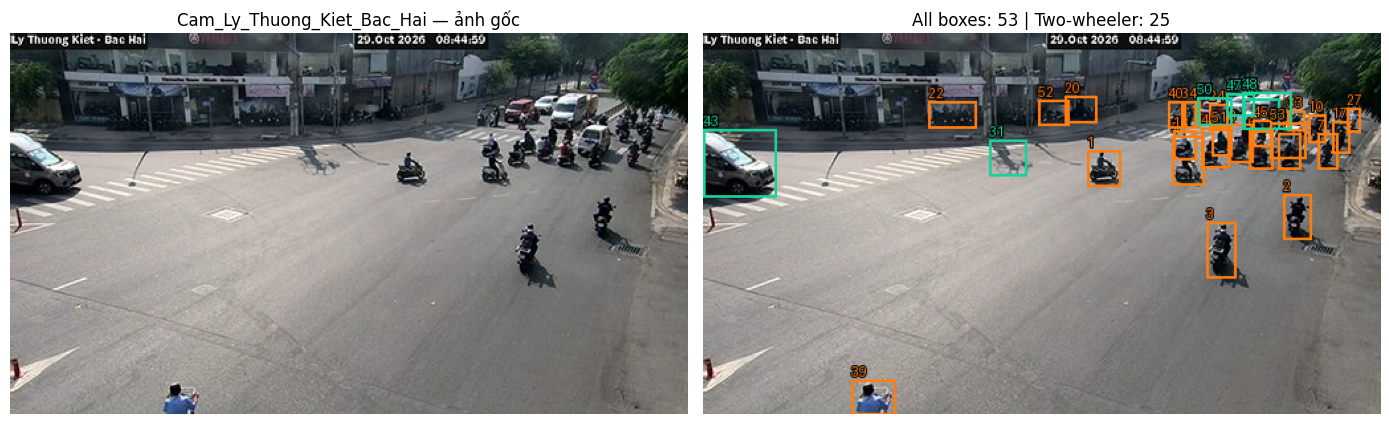


CAMERA: Cam_Thanh_Thai_To_Hien_Thanh — 5 frame


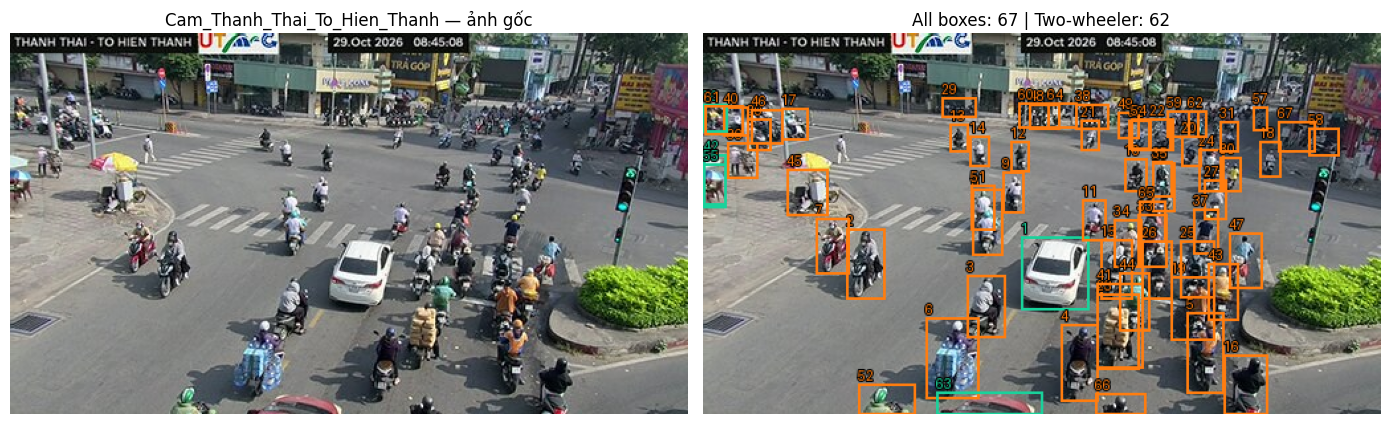


CAMERA: Cam_To_Hien_Thanh_1 — 6 frame


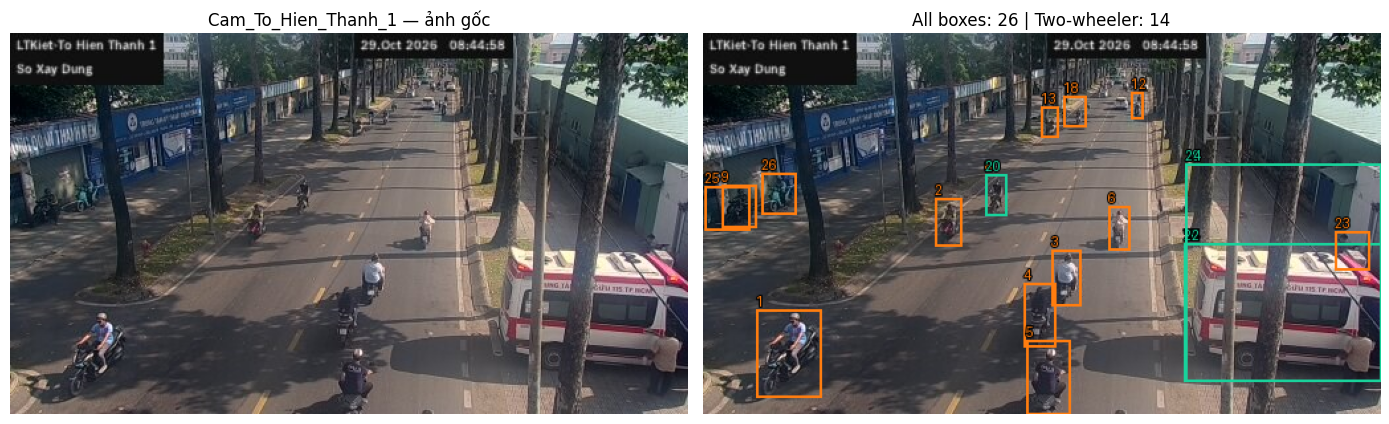


CAMERA: Cam_To_Hien_Thanh_2 — 6 frame


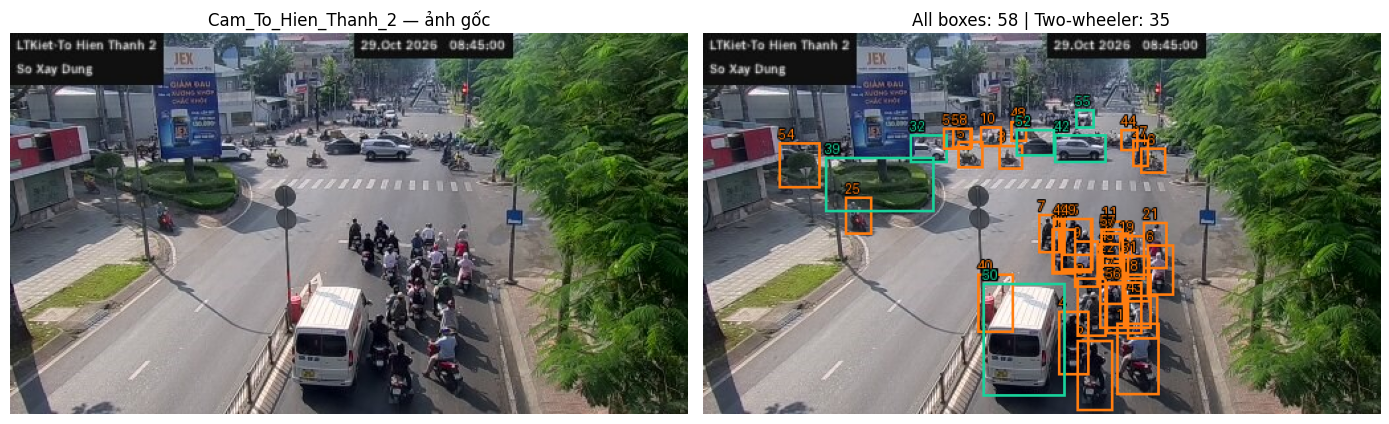

  Đã detect 20 frame mới, skip 0 | Cam_To_Hien_Thanh_2: 3/6

CAMERA: Cam_To_Hien_Thanh_Su_Van_Hanh — 6 frame


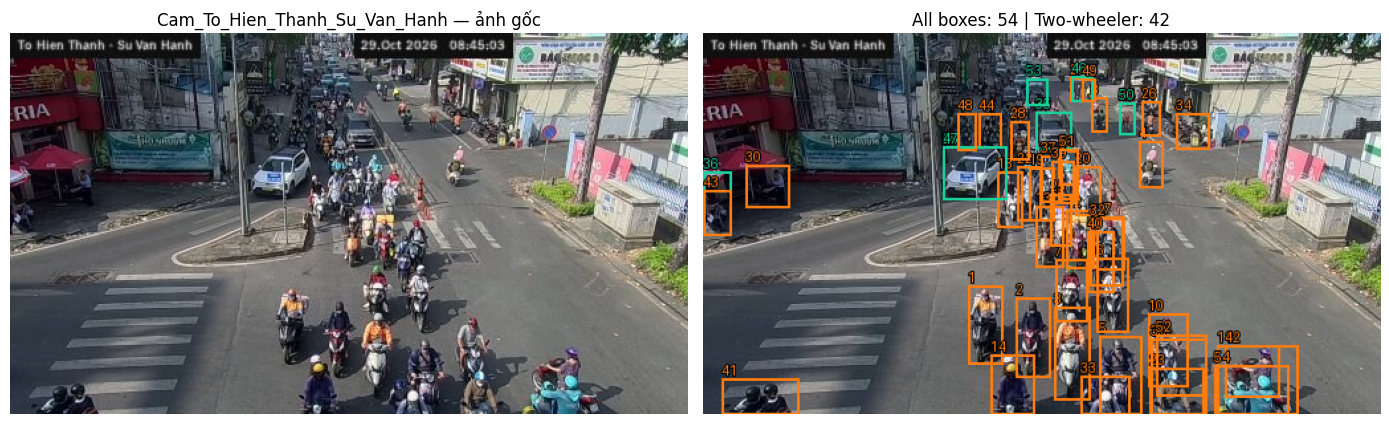


HOÀN THÀNH BATCH DETECTION — mỗi frame chỉ có một ảnh all_boxes
Đã ghi 29 frame mới, skip 0, lỗi trong lần chạy này: 0
Thời gian cell detect: 0.13 phút


,camera,frames_discovered_this_run,frames_success_in_manifest,frames_errors_this_run,sum_detections_across_frames,sum_two_wheeler_detections_across_frames,avg_detections_per_successful_frame,avg_two_wheelers_per_successful_frame
0,Cam_Ly_Thuong_Kiet_Bac_Hai,6,6,0,358,252,59.667,42.0
1,Cam_Thanh_Thai_To_Hien_Thanh,5,5,0,351,282,70.200,56.4
2,Cam_To_Hien_Thanh_1,6,6,0,230,153,38.333,25.5
3,Cam_To_Hien_Thanh_2,6,6,0,388,210,64.667,35.0
4,Cam_To_Hien_Thanh_Su_Van_Hanh,6,6,0,277,177,46.167,29.5


In [7]:
output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(parents=True, exist_ok=True)

# Đảm bảo không trộn kết quả có khác cấu hình hoặc cấu trúc output.
run_config = {
    "input_root": str(input_root), "camera_folders": CAMERA_FOLDERS,
    "frame_filter": "frame_* + extensions: .jpg,.jpeg,.png,.webp",
    "model_choice": MODEL_CHOICE, "weights_sha256": weights_sha256,
    "image_size": IMAGE_SIZE, "confidence": CONFIDENCE, "nms_iou": NMS_IOU,
    "max_detections": MAX_DETECTIONS, "test_time_augmentation": TEST_TIME_AUGMENTATION,
    "class_names": class_names, "two_wheeler_class_ids": TWO_WHEELER_CLASS_IDS,
    "show_confidence_on_box": SHOW_CONFIDENCE_ON_BOX,
    "show_index_on_box": SHOW_INDEX_ON_BOX,
    "output_image_format": OUTPUT_IMAGE_FORMAT.lower(), "jpeg_quality": JPEG_QUALITY,
    "output_contract": "one_all_boxes_image_per_frame_no_per_frame_csv_json",
}
config_path = output_dir / "run_config.json"
if config_path.exists():
    old_config = json.loads(config_path.read_text(encoding="utf-8"))
    if old_config != json.loads(json.dumps(run_config)):
        raise RuntimeError(
            f"OUTPUT_DIR đã chứa kết quả với cấu hình khác: {output_dir}. "
            "Hãy dùng OUTPUT_DIR/ZIP_PATH mới hoặc xóa output cũ để tránh trộn kết quả."
        )
else:
    if any(output_dir.iterdir()):
        raise RuntimeError(f"{output_dir} có dữ liệu nhưng thiếu run_config.json; hãy dùng OUTPUT_DIR mới.")
    config_path.write_text(json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8")

if OUTPUT_IMAGE_FORMAT.lower() not in ("jpg", "png"):
    raise ValueError('OUTPUT_IMAGE_FORMAT chỉ nhận "jpg" hoặc "png".')
if LOG_EVERY_N_FRAMES < 1:
    raise ValueError("LOG_EVERY_N_FRAMES phải >= 1.")


def get_output_path(image_path):
    relative = image_path.relative_to(input_root)
    # Phân biệt frame_0001.jpg và frame_0001.png nếu trùng stem.
    prefix = f"{image_path.stem}_{image_path.suffix.lstrip('.').lower()}_{MODEL_CHOICE}"
    ext = OUTPUT_IMAGE_FORMAT.lower()
    return output_dir / relative.parent / f"{prefix}_all_boxes.{ext}"


def relative_output(path):
    return str(path.relative_to(output_dir)).replace("\\", "/")


manifest_columns = [
    "camera", "frame", "input_relative_path", "timestamp_from_filename",
    "width", "height", "total_predictions", "two_wheeler_predictions",
    "inference_seconds", "status", "all_boxes_file"
]
manifest_path = output_dir / "manifest.csv"
# Resume không cần tạo metadata file riêng cho từng ảnh.
previous = {}
if manifest_path.is_file():
    prev_df = pd.read_csv(manifest_path, keep_default_na=False)
    if all(col in prev_df.columns for col in manifest_columns):
        for item in prev_df.to_dict(orient="records"):
            previous[str(item["input_relative_path"])] = item
    else:
        raise RuntimeError("manifest.csv cũ có schema khác. Hãy sử dụng OUTPUT_DIR mới.")

manifest_by_path = dict(previous)
error_rows = []
preview_counts = Counter()
newly_processed = 0
skipped = 0
t0 = time.perf_counter()


def save_manifest_checkpoint():
    # Chỉ một manifest chung, ghi atomic để có thể resume khi Kaggle bị ngắt.
    frame = pd.DataFrame(list(manifest_by_path.values()), columns=manifest_columns)
    tmp = manifest_path.with_suffix(".csv.tmp")
    frame.to_csv(tmp, index=False)
    tmp.replace(manifest_path)


for camera, frame_paths in camera_files.items():
    print(f"\n{'=' * 65}\nCAMERA: {camera} — {len(frame_paths)} frame")
    for local_index, image_path in enumerate(frame_paths, start=1):
        key = str(image_path.relative_to(input_root)).replace("\\", "/")
        out_path = get_output_path(image_path)
        try:
            prior = previous.get(key)
            if (SKIP_COMPLETED_FRAMES and prior is not None
                    and prior.get("all_boxes_file", "") == relative_output(out_path)
                    and out_path.is_file()):
                # Giữ các thống kê gốc, không inference lại.
                manifest_by_path[key] = {**prior, "status": "skipped_existing"}
                skipped += 1
                continue

            with Image.open(image_path) as source_img:
                image = source_img.convert("RGB")
            W, H = image.size
            df, elapsed = detect_one_frame(image_path)
            out_path.parent.mkdir(parents=True, exist_ok=True)

            # ĐÚNG MỘT file hình/frame: all_boxes, không zoom, không two_wheelers_only.
            all_boxes_img = draw_boxes(image, df)
            tmp_image = out_path.with_name(out_path.name + ".tmp")
            save_visualization(all_boxes_img, tmp_image)
            tmp_image.replace(out_path)

            manifest_by_path[key] = {
                "camera": camera, "frame": image_path.name,
                "input_relative_path": key,
                "timestamp_from_filename": frame_timestamp_from_name(image_path),
                "width": W, "height": H,
                "total_predictions": int(len(df)),
                "two_wheeler_predictions": int(df.is_two_wheeler.sum()),
                "inference_seconds": round(elapsed, 4),
                "status": "processed", "all_boxes_file": relative_output(out_path),
            }
            newly_processed += 1

            if preview_counts[camera] < PREVIEW_PER_CAMERA:
                preview_counts[camera] += 1
                fig, axes = plt.subplots(1, 2, figsize=(14, 5))
                axes[0].imshow(image)
                axes[0].set_title(f"{camera} — ảnh gốc")
                axes[0].axis("off")
                axes[1].imshow(all_boxes_img)
                axes[1].set_title(f"All boxes: {len(df)} | Two-wheeler: {int(df.is_two_wheeler.sum())}")
                axes[1].axis("off")
                plt.tight_layout(); plt.show(); plt.close(fig)

            if newly_processed % LOG_EVERY_N_FRAMES == 0:
                save_manifest_checkpoint()
                print(f"  Đã detect {newly_processed} frame mới, skip {skipped} | {camera}: {local_index}/{len(frame_paths)}")
        except Exception as exc:
            error_rows.append({
                "camera": camera, "input_relative_path": key,
                "error_type": type(exc).__name__, "error": str(exc)[:1000]
            })
            print(f"  ⚠️ Lỗi frame {image_path.name}: {type(exc).__name__}: {exc}")
            # Một frame hỏng không làm dừng cả batch.
    save_manifest_checkpoint()

manifest = pd.DataFrame(list(manifest_by_path.values()), columns=manifest_columns)
errors = pd.DataFrame(error_rows, columns=["camera", "input_relative_path", "error_type", "error"])
save_manifest_checkpoint()
errors.to_csv(output_dir / "errors.csv", index=False)

summary_rows = []
for camera in CAMERA_FOLDERS:
    part = manifest.loc[manifest.camera == camera]
    summary_rows.append({
        "camera": camera, "frames_discovered_this_run": len(camera_files[camera]),
        "frames_success_in_manifest": len(part),
        "frames_errors_this_run": int((errors.camera == camera).sum()),
        "sum_detections_across_frames": int(part.total_predictions.sum()),
        "sum_two_wheeler_detections_across_frames": int(part.two_wheeler_predictions.sum()),
        "avg_detections_per_successful_frame": round(float(part.total_predictions.mean()), 3) if len(part) else None,
        "avg_two_wheelers_per_successful_frame": round(float(part.two_wheeler_predictions.mean()), 3) if len(part) else None,
    })
camera_summary = pd.DataFrame(summary_rows)
camera_summary.to_csv(output_dir / "camera_summary.csv", index=False)

print("\nHOÀN THÀNH BATCH DETECTION — mỗi frame chỉ có một ảnh all_boxes")
print(f"Đã ghi {newly_processed} frame mới, skip {skipped}, lỗi trong lần chạy này: {len(errors)}")
print(f"Thời gian cell detect: {(time.perf_counter() - t0)/60:.2f} phút")
display(camera_summary)
if len(errors):
    display(errors.head(20))

## 7) Nén một ZIP — chỉ ảnh `all_boxes` và 4 file tổng hợp

In [8]:
zip_path = Path(ZIP_PATH)
zip_path.parent.mkdir(parents=True, exist_ok=True)
if zip_path.resolve() == output_dir.resolve() or output_dir.resolve() in zip_path.resolve().parents:
    raise ValueError("ZIP_PATH phải nằm bên ngoài OUTPUT_DIR để tránh zip tự chứa chính nó.")

t0_zip = time.perf_counter()
files_to_zip = sorted(p for p in output_dir.rglob("*") if p.is_file() and not p.name.endswith(".tmp"))
with zipfile.ZipFile(zip_path, mode="w", compression=zipfile.ZIP_DEFLATED, compresslevel=1, allowZip64=True) as zf:
    for file_path in files_to_zip:
        relative_name = (Path(output_dir.name) / file_path.relative_to(output_dir)).as_posix()
        zf.write(file_path, arcname=relative_name)

# ZIP integrity check: xác minh directory index và sự hiện diện của manifest.
with zipfile.ZipFile(zip_path) as zf:
    archive_names = set(zf.namelist())
    expected = f"{output_dir.name}/manifest.csv"
    if expected not in archive_names:
        raise RuntimeError(f"ZIP thiếu {expected}.")
print("ZIP đã tạo:", zip_path)
print("Dung lượng ZIP (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))
print("Số file trong ZIP:", len(files_to_zip))
print("Thời gian nén (giây):", round(time.perf_counter() - t0_zip, 2))
print("Trên Kaggle: Output → /kaggle/working →", zip_path.name, "→ Download")
if len(errors):
    print(f"⚠️ Có {len(errors)} frame xử lý lỗi; xem errors.csv trong ZIP. ZIP vẫn được tạo với các frame thành công.")

ZIP đã tạo: /kaggle/working/traffic_detection_RTDETRv2_BMD45_5cams_all_boxes_only.zip
Dung lượng ZIP (MB): 7.09
Số file trong ZIP: 33
Thời gian nén (giây): 0.23
Trên Kaggle: Output → /kaggle/working → traffic_detection_RTDETRv2_BMD45_5cams_all_boxes_only.zip → Download


## 8) Cấu trúc output

```text
/kaggle/working/
├── traffic_detection_RTDETRv2_BMD45_5cams_all_boxes_only.zip       ← TẢI FILE NÀY
└── traffic_detection_RTDETRv2_BMD45_all_boxes_only/
    ├── run_config.json
    ├── manifest.csv            ← 1 dòng / frame đã xử lý, kèm count và đường dẫn ảnh
    ├── camera_summary.csv      ← thống kê tổng hợp mỗi camera
    ├── errors.csv              ← lỗi của lần chạy gần nhất
    ├── Cam_Ly_Thuong_Kiet_Bac_Hai/
    │   ├── frame_000001_..._jpg_rtdetrv2_x_all_boxes.png
    │   └── frame_000002_..._jpg_rtdetrv2_x_all_boxes.png
    ├── Cam_Thanh_Thai_To_Hien_Thanh/
    ├── Cam_To_Hien_Thanh_1/
    ├── Cam_To_Hien_Thanh_2/
    └── Cam_To_Hien_Thanh_Su_Van_Hanh/
```

**Mỗi frame có đúng 1 ảnh kết quả** (`*_all_boxes.png` hoặc `.jpg`), không thêm `*_two_wheelers.*`, `*_crowded_zoom.*`, `*_detections.csv`, `*_threshold_counts.csv` hay `*_metadata.json`.

`manifest.csv` là file cấp dataset dùng ghi nhận kết quả và hỗ trợ resume, không phải file riêng theo frame. Không đưa input `summary.json`/`metadata.csv` vào ZIP. Preview trong Kaggle chỉ hiển thị, không ghi ảnh phụ.

- Chạy tất cả: `MAX_FRAMES_PER_CAMERA = None`.
- Chạy thử 2 frame/camera: `MAX_FRAMES_PER_CAMERA = 2`, sau đó đổi lại `None` để chạy tiếp.
- Thay model/threshold/cách vẽ → chọn `OUTPUT_DIR` mới để tránh trộn các run.
- Các count chỉ là số đối tượng mô hình phát hiện tại thời điểm chụp ảnh; không phải traffic flow, density chuẩn hay ground truth.
